In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,f1_score
from sklearn.model_selection import train_test_split
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet
from wordcloud import WordCloud,STOPWORDS
import re,string,unicodedata
from string import punctuation
import warnings
warnings.filterwarnings("ignore")


In [24]:
df = pd.read_csv("IMDB-Dataset.csv",encoding="latin-1")

df.head(5)

,Ratings,Reviews,Movies,Resenhas
0,1.0,*Disclaimer: I only watched this movie as a co...,Disaster Movie,* IsenÃ§Ã£o de responsabilidade: eu sÃ³ assist...
1,1.0,I am writing this in hopes that this gets put ...,Disaster Movie,Estou escrevendo isso na esperanÃ§a de que iss...
2,1.0,"Really, I could write a scathing review of thi...",Disaster Movie,"Realmente, eu poderia escrever uma crÃ­tica co..."
3,1.0,If you saw the other previous spoof movies by ...,Disaster Movie,Se vocÃª viu os outros filmes falsificados ant...
4,1.0,This movie I saw a day early for free and I st...,Disaster Movie,Este filme eu vi um dia cedo de graÃ§a e ainda...


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 4 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Ratings   150000 non-null  float64
 1   Reviews   150000 non-null  object 
 2   Movies    149975 non-null  object 
 3   Resenhas  150000 non-null  object 
dtypes: float64(1), object(3)
memory usage: 4.6+ MB


#### Data Cleaning and Preprocessing

In [29]:
# customize stop words
from nltk.corpus import stopwords
stop_words=stopwords.words("english")
new_stop_words=["Movie","film","one","would","shall","could","might"]
stop_words.extend(new_stop_words)
stop_words.remove("not")
stop_words=set(stop_words)

In [38]:
# remove special characters
def remove_special(content):
    return re.sub(r'\[[^&@#!]]*\]', '', content)

# remove URL's
def remove_url(content):
    return re.sub(r'http\S+','',content)

# removing stop words 
def remove_stopwords(content):
    clean_data=[]
    for i in content.split():
        if i.strip().lower() not in stop_words and i.strip().lower().isalpha():
           clean_data.append(i.strip().lower())
    return " ".join(clean_data)

# Expansion of english contractions
def contraction_expansion(content):
    content=re.sub(r"won\'t","would not",content)
    content=re.sub(r"can\'t","can not",content)
    content=re.sub(r"don\'t","do not",content)
    content=re.sub(r"shouldn\'t","should not",content)
    content=re.sub(r"needn\'t","need not",content)
    content=re.sub(r"hasn\'t","has not",content)
    content=re.sub(r"weren\'t","were not",content)
    content=re.sub(r"mightn\'t","might not",content)
    content=re.sub(r"didn\'t","did not",content)
    content=re.sub(r"n\'t","not",content)
    content=re.sub(r"\'re","are",content)
    content=re.sub(r"\'s","is",content)
    content=re.sub(r"\'d","would",content)
    content=re.sub(r"\'ll","will",content)
    content=re.sub(r"\'ve","have",content)
    content=re.sub(r"\'m","am",content)
    return content



def data_cleaning(content):
    content=remove_special(content)
    content=remove_url(content)
    content=remove_stopwords(content)
    content=contraction_expansion(content)
    return content



In [39]:
# Data cleaning
df['Reviews']=df['Reviews'].apply(data_cleaning)
df['Reviews'].head(5)

0    watched movie conditional see films caught dea...
1    writing hopes gets put previous review anyone ...
2    write scathing review turd going making observ...
3    saw previous spoof movies two horrible know al...
4    movie saw day early free still feel like got r...
Name: Reviews, dtype: object

#### Data Overview

In [40]:
df.isna().sum()

Ratings      0
Reviews      0
Movies      25
Resenhas     0
dtype: int64

In [41]:
df['Ratings'].describe()

count    150000.000000
mean          5.500000
std           2.872291
min           1.000000
25%           3.000000
50%           5.500000
75%           8.000000
max          10.000000
Name: Ratings, dtype: float64

In [42]:
df['Reviews'].describe()

count     150000
unique    149743
top             
freq          11
Name: Reviews, dtype: object

In [43]:
print("Unique reviews:%s" % df.Reviews.nunique())
print("No. of ratings:%s" % df.Ratings.count())
print("Unique movie names:%s" % df.Movies.nunique())

Unique reviews:149743
No. of ratings:150000
Unique movie names:14206


#### Exploratory data analysis

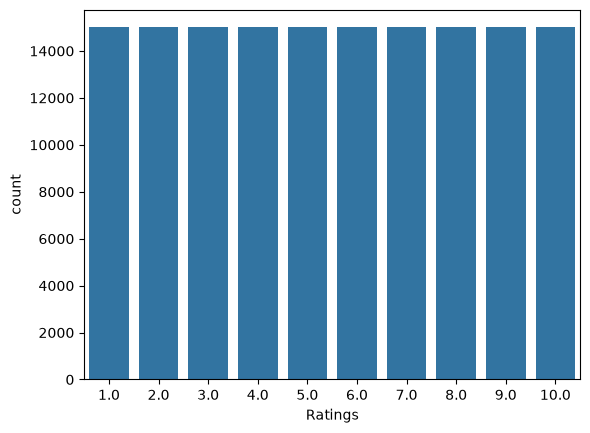

Ratings
1.0     15000
2.0     15000
4.0     15000
3.0     15000
5.0     15000
6.0     15000
8.0     15000
7.0     15000
10.0    15000
9.0     15000
Name: count, dtype: int64


In [44]:
# class imbalance
sns.countplot(x=df['Ratings'])
plt.show()
print(df['Ratings'].value_counts())

(np.float64(-0.5), np.float64(1499.5), np.float64(799.5), np.float64(-0.5))

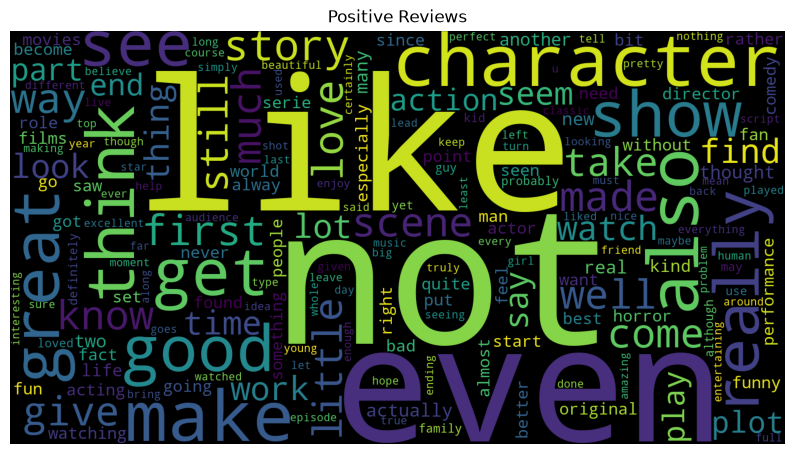

In [47]:
'''-----Visualization of important words from positive reviews'''
sentences=df['Reviews']
pos=' '.join(map(str,sentences[df['Ratings']>=7]))
neg=' '.join(map(str,sentences[df['Ratings']<=4]))

pos_wordcloud=WordCloud(width = 1500,height=800,
                        background_color='black',
                        stopwords = stop_words,
                        min_font_size=15).generate(pos)

plt.figure(figsize=(10,10))
plt.imshow(pos_wordcloud)
plt.title('Positive Reviews')
plt.axis('off')

(np.float64(-0.5), np.float64(1499.5), np.float64(799.5), np.float64(-0.5))

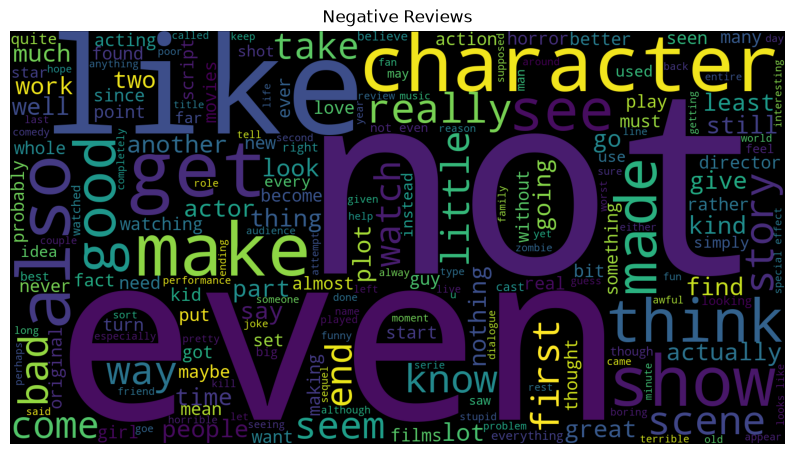

In [50]:
neg_wordcloud=WordCloud(width=1500,
                        height=800,
                        background_color="black",
                        stopwords=stop_words,
                        min_font_size=15).generate(neg)

plt.figure(figsize=(10,10))
plt.imshow(neg_wordcloud)
plt.title('Negative Reviews')
plt.axis('off')

#### Basic Statistic Of Review data